# Simulated SLM：相位生成与显示

这个 notebook 演示从相位生成到 simulated backend 显示帧的完整流程：

1. 创建一个虚拟 SLM；
2. 在不同区域生成涡旋、透镜和 blazed_grating 相位；
3. 将这些相位组合为一张完整的相位图并可视化；
4. 使用 slm.load_phase() 写入 simulated backend；
5. 读取并显示 backend 当前的 RGB 帧。

相位在 qtools.slm 中以弧度保存，只有在 load_phase() 时才会被量化为显示灰度值。运行本示例需要可选依赖 slmsuite，可以使用 pip install qtools[slm-simulated] 安装。

In [12]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

from qtools.slm import SLM
from qtools.slm.phase import superposition

PHASE_PERIOD = 2 * np.pi

## 1. 创建 simulated SLM

示例使用较小的 512 × 512 分辨率以便快速交互式运行。像素间距和波长用于相位函数的物理计算，并不代表某一台真实 SLM 的校准参数。

In [13]:
slm = SLM(
    'simulated',
    resolution=(512, 512),
    pitch_um=6.4,
    wavelength=532e-9,
)

print(f'backend: {slm.name}')
print(f'model: {slm.model}')
print(f'resolution (width, height): {slm.resolution}')
print(f'array shape (height, width): {slm.shape}')

canvas = slm.create_canvas()
left, middle, right = canvas.partition(axis='x', ratios=(1, 1, 1))
print('region bounds:', left.bounds, middle.bounds, right.bounds)

[INF] 09:29:36 SimulatedSLM #2 Initialized SimulatedSLM.
backend: simulated
model: slmsuite-SimulatedSLM
resolution (width, height): (512, 512)
array shape (height, width): (512, 512)
region bounds: (0, 171, 0, 512) (171, 341, 0, 512) (341, 512, 0, 512)


## 2. 生成三种局部相位

每个 PhaseRegion 都会返回一张完整 SLM 尺寸的 PhaseMask；区域之外的相位保持为零。这里分别生成一阶涡旋、焦距为 0.5 m 的透镜，以及 16 像素周期的 blazed_grating 光栅。

In [14]:
vortex_phase = left.spiral(order=1)
lens_phase = middle.lens(f=0.5)
blazed_grating_phase = right.blazed_grating(period=16, angle=0.0)

phase_masks = {
    'vortex': vortex_phase,
    'lens': lens_phase,
    'blazed_grating': blazed_grating_phase,
}

for name, phase_mask in phase_masks.items():
    assert phase_mask.shape == slm.shape
    assert np.isfinite(phase_mask.array).all()
    print(f'{name}: shape={phase_mask.shape}, region={phase_mask.region_bounds}')

vortex: shape=(512, 512), region=(0, 171, 0, 512)
lens: shape=(512, 512), region=(171, 341, 0, 512)
blazed_grating: shape=(512, 512), region=(341, 512, 0, 512)


为了显示相位，将弧度值包裹到 [0, 2π)。这只是可视化操作，不会修改 PhaseMask 中保存的原始相位。

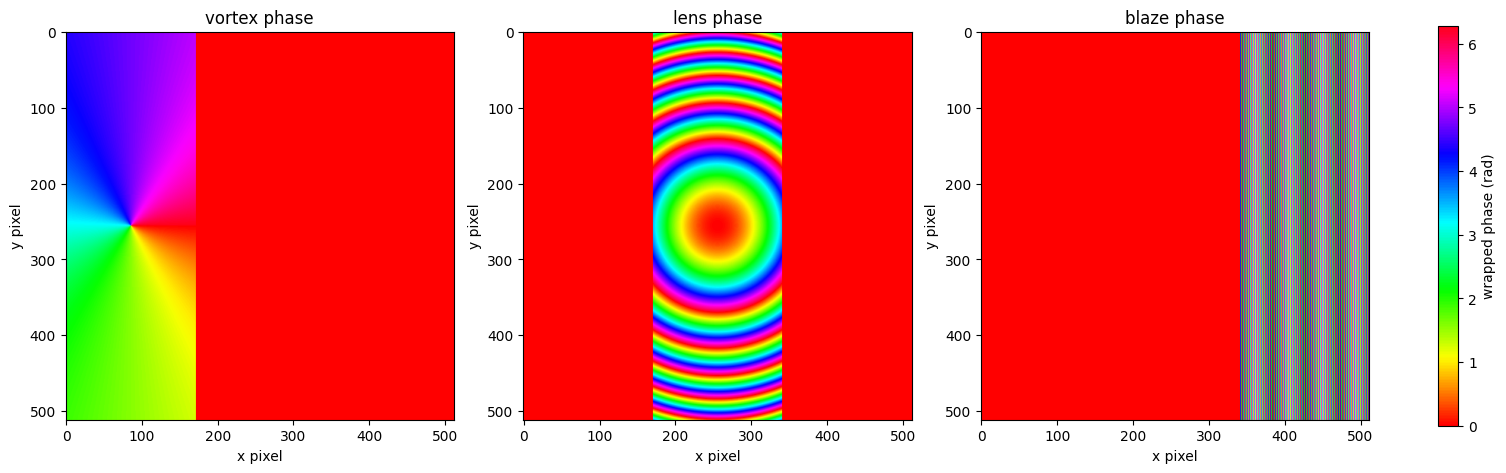

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
images = []
for axis, (title, phase_mask) in zip(axes, phase_masks.items()):
    wrapped_phase = np.mod(phase_mask.array, PHASE_PERIOD)
    image = axis.imshow(
        wrapped_phase,
        cmap='hsv',
        vmin=0,
        vmax=PHASE_PERIOD,
        origin='upper',
    )
    images.append(image)
    axis.set_title(f'{title} phase')
    axis.set_xlabel('x pixel')
    axis.set_ylabel('y pixel')

fig.colorbar(images[0], ax=axes, label='wrapped phase (rad)')
plt.show()

## 3. 组合相位并显示

compose() 会检查这些带区域信息的相位是否属于同一个 SLM 几何上下文、是否重叠，然后将它们合并为一张完整相位图。

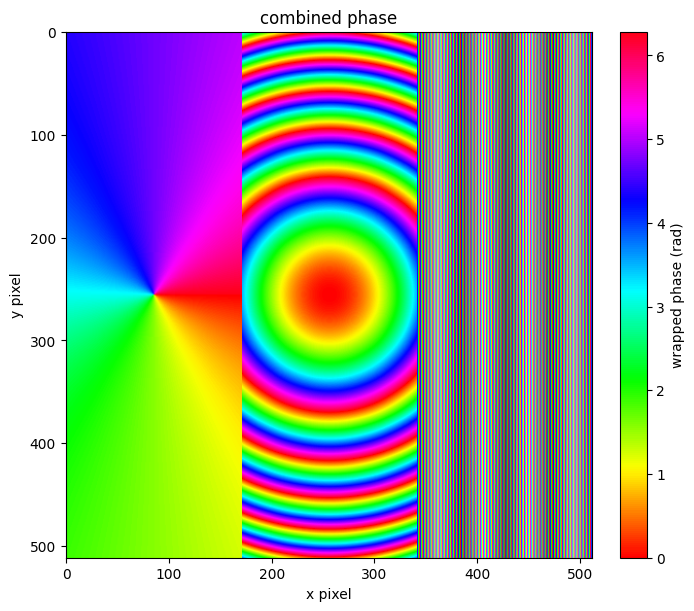

In [16]:
combined_phase = canvas.compose(vortex_phase, lens_phase, blazed_grating_phase)

assert combined_phase.shape == slm.shape
assert np.isfinite(combined_phase.array).all()
assert combined_phase.region_bounds is None

wrapped_combined = np.mod(combined_phase.array, PHASE_PERIOD)
fig, axis = plt.subplots(figsize=(7, 6), constrained_layout=True)
image = axis.imshow(
    wrapped_combined,
    cmap='hsv',
    vmin=0,
    vmax=PHASE_PERIOD,
    origin='upper',
)
axis.set_title('combined phase')
axis.set_xlabel('x pixel')
axis.set_ylabel('y pixel')
fig.colorbar(image, ax=axis, label='wrapped phase (rad)')
plt.show()

## 4. 写入 simulated backend

load_phase() 会把弧度相位转换为 8-bit 显示数据，再交给 simulated backend 的内存显示。这里不会连接真实显示器。simulated backend 返回 RGB transport frame；本示例中三个通道相同，因此最后使用第一个通道作为灰度显示。

In [17]:
with slm:
    slm.load_phase(combined_phase)
    current_frame = slm.get_current_image()

assert current_frame is not None
assert current_frame.shape == (slm.shape[0], slm.shape[1], 3)
assert current_frame.dtype == np.uint8

print(f'current frame shape: {current_frame.shape}')
print(f'current frame dtype: {current_frame.dtype}')
print(f'gray-level range: {current_frame.min()}..{current_frame.max()}')

current frame shape: (512, 512, 3)
current frame dtype: uint8
gray-level range: 0..255


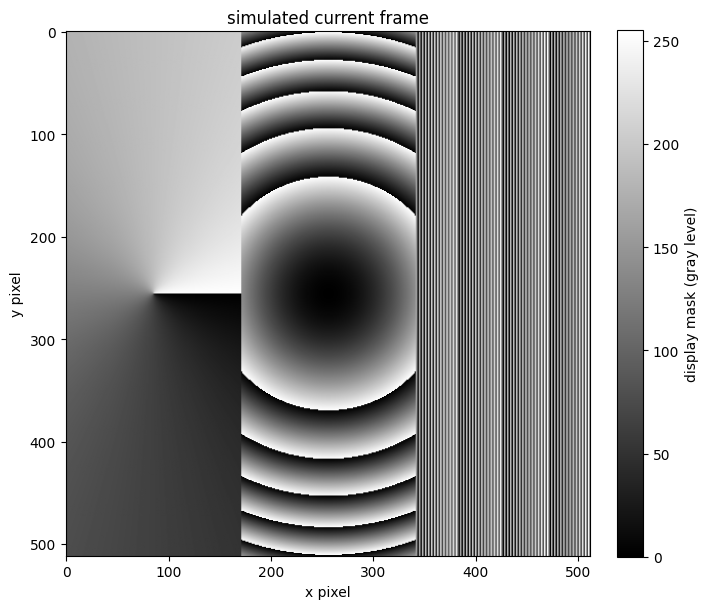

In [18]:
fig, axis = plt.subplots(figsize=(7, 6), constrained_layout=True)
gray_frame = current_frame[..., 0]
image = axis.imshow(
    gray_frame,
    cmap='gray',
    vmin=0,
    vmax=255,
    origin='upper',
)
axis.set_title('simulated current frame')
axis.set_xlabel('x pixel')
axis.set_ylabel('y pixel')
fig.colorbar(image, ax=axis, label='display mask (gray level)')
plt.show()

## 5. 涡旋相位的相干叠加

`superposition()` 接收已有的 `PhaseMask`，把每一张相位图解释为单位复振幅 `exp(1j * phase)`，按 `coefficients` 加权后计算复场的 `np.angle()`。系数同时表示相对振幅和相对相位；这里演示 PDF 中的 `l=0 + l=1` 和 `l=0 - l=1`：

```python
field = amplitude_0 * exp(1j * spiral_0) + amplitude_1 * exp(1j * delta) * exp(1j * spiral_1)
phase = angle(field)
```

其中 `coefficients=(1, 1)` 是同相叠加，`coefficients=(1, -1)` 是相对相位为 `π` 的叠加。

In [19]:
spiral_0 = canvas.spiral(order=0)
spiral_1 = canvas.spiral(order=1)

plus_phase = superposition(
    spiral_0,
    spiral_1,
    coefficients=(1.0, 1.0),
)
minus_phase = superposition(
    spiral_0,
    spiral_1,
    coefficients=(1.0, -1.0),
)

# 任意复系数也可以直接表示相对相位，例如 (1, 1j)。
quadrature_phase = superposition(
    canvas.spiral(order=1),
    canvas.spiral(order=2),
    coefficients=(1.0, 1j),
)
assert np.isfinite(quadrature_phase.array).all()

superposition_phases = {
    'l=0 + l=1': plus_phase,
    'l=0 - l=1': minus_phase,
}

for name, phase_mask in superposition_phases.items():
    assert phase_mask.shape == slm.shape
    assert np.isfinite(phase_mask.array).all()
    print(f'{name}: shape={phase_mask.shape}, dtype={phase_mask.array.dtype}')

l=0 + l=1: shape=(512, 512), dtype=float64
l=0 - l=1: shape=(512, 512), dtype=float64


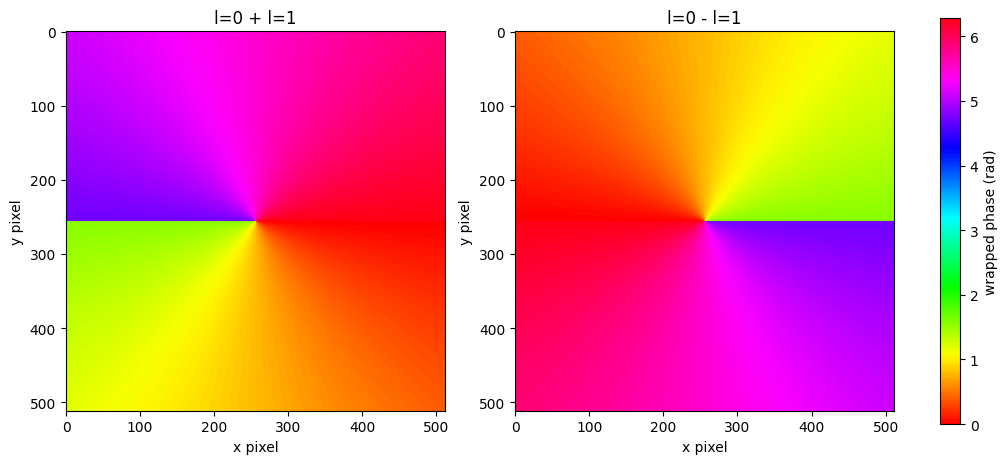

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
images = []
for axis, (title, phase_mask) in zip(axes, superposition_phases.items()):
    image = axis.imshow(
        np.mod(phase_mask.array, PHASE_PERIOD),
        cmap='hsv',
        vmin=0,
        vmax=PHASE_PERIOD,
        origin='upper',
    )
    images.append(image)
    axis.set_title(title)
    axis.set_xlabel('x pixel')
    axis.set_ylabel('y pixel')
fig.colorbar(images[0], ax=axes, label='wrapped phase (rad)')
plt.show()

l=0 + l=1: type=DisplayMask, shape=(512, 512), dtype=uint8
l=0 - l=1: type=DisplayMask, shape=(512, 512), dtype=uint8


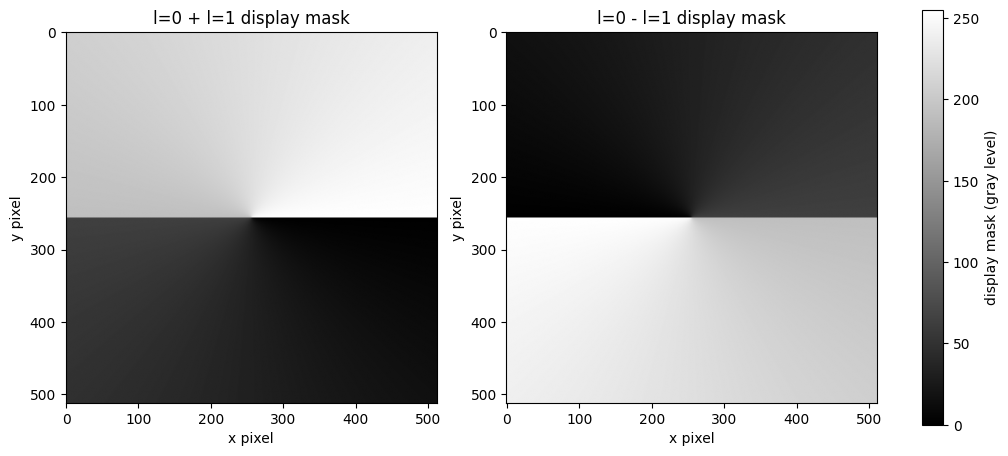

In [21]:
display_masks = {
    name: phase_mask.to_display(bits=8)
    for name, phase_mask in superposition_phases.items()
}

for name, display_mask in display_masks.items():
    print(
        f'{name}: type={type(display_mask).__name__}, '
        f'shape={display_mask.shape}, dtype={display_mask.array.dtype}'
    )

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
images = []
for axis, (title, display_mask) in zip(axes, display_masks.items()):
    image = axis.imshow(
        display_mask.array,
        cmap='gray',
        vmin=0,
        vmax=255,
        origin='upper',
    )
    images.append(image)
    axis.set_title(f'{title} display mask')
    axis.set_xlabel('x pixel')
    axis.set_ylabel('y pixel')
fig.colorbar(images[0], ax=axes, label='display mask (gray level)')
plt.show()

现在已经完成了从解析相位到 simulated SLM 显示帧的流程。current_frame 是 backend 当前保存的 8-bit RGB 图像；如果要加载下一张相位，只需重新生成 PhaseMask 并再次调用 slm.load_phase()。